In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Superstore_Sales.csv")
df

,Order ID,Order Date,Ship Date,Region,Category,Sub-Category,Product Name,Sales,Quantity,Profit,Customer Segment
0,ORD1000,2023-01-01,2023-01-03,Central,Technology,Chairs,Product B,365.04,8,19.84,Corporate
1,ORD1001,2023-01-02,2023-01-04,South,Technology,Accessories,Product A,996.25,6,23.97,Corporate
2,ORD1002,2023-01-03,2023-01-05,East,Furniture,Phones,Product C,727.23,3,58.93,Home Office
3,ORD1003,2023-01-04,2023-01-06,Central,Furniture,Binders,Product A,445.78,9,70.72,Home Office
4,ORD1004,2023-01-05,2023-01-07,Central,Office Supplies,Storage,Product D,763.39,2,219.91,Consumer
...,...,...,...,...,...,...,...,...,...,...,...
195,ORD1195,2023-07-15,2023-07-17,West,Office Supplies,Binders,Product B,906.95,4,108.07,Corporate
196,ORD1196,2023-07-16,2023-07-18,West,Technology,Chairs,Product C,618.40,6,70.73,Consumer
197,ORD1197,2023-07-17,2023-07-19,South,Furniture,Storage,Product A,925.66,6,250.67,Home Office
198,ORD1198,2023-07-18,2023-07-20,East,Furniture,Tables,Product A,104.77,8,67.00,Corporate


In [3]:
df.head()

,Order ID,Order Date,Ship Date,Region,Category,Sub-Category,Product Name,Sales,Quantity,Profit,Customer Segment
0,ORD1000,2023-01-01,2023-01-03,Central,Technology,Chairs,Product B,365.04,8,19.84,Corporate
1,ORD1001,2023-01-02,2023-01-04,South,Technology,Accessories,Product A,996.25,6,23.97,Corporate
2,ORD1002,2023-01-03,2023-01-05,East,Furniture,Phones,Product C,727.23,3,58.93,Home Office
3,ORD1003,2023-01-04,2023-01-06,Central,Furniture,Binders,Product A,445.78,9,70.72,Home Office
4,ORD1004,2023-01-05,2023-01-07,Central,Office Supplies,Storage,Product D,763.39,2,219.91,Consumer


In [4]:
df.tail()

,Order ID,Order Date,Ship Date,Region,Category,Sub-Category,Product Name,Sales,Quantity,Profit,Customer Segment
195,ORD1195,2023-07-15,2023-07-17,West,Office Supplies,Binders,Product B,906.95,4,108.07,Corporate
196,ORD1196,2023-07-16,2023-07-18,West,Technology,Chairs,Product C,618.40,6,70.73,Consumer
197,ORD1197,2023-07-17,2023-07-19,South,Furniture,Storage,Product A,925.66,6,250.67,Home Office
198,ORD1198,2023-07-18,2023-07-20,East,Furniture,Tables,Product A,104.77,8,67.00,Corporate
199,ORD1199,2023-07-19,2023-07-21,Central,Furniture,Phones,Product B,977.56,1,84.78,Home Office


In [6]:
df.shape

(200, 11)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order ID          200 non-null    object 
 1   Order Date        200 non-null    object 
 2   Ship Date         200 non-null    object 
 3   Region            200 non-null    object 
 4   Category          200 non-null    object 
 5   Sub-Category      200 non-null    object 
 6   Product Name      200 non-null    object 
 7   Sales             200 non-null    float64
 8   Quantity          200 non-null    int64  
 9   Profit            200 non-null    float64
 10  Customer Segment  200 non-null    object 
dtypes: float64(2), int64(1), object(8)
memory usage: 17.3+ KB


In [9]:
df.describe()

,Sales,Quantity,Profit
count,200.000000,200.000000,200.000000
mean,540.325100,5.025000,115.678000
std,258.476463,2.588023,107.824164
min,102.340000,1.000000,-99.060000
25%,332.037500,3.000000,39.332500
50%,543.690000,5.000000,115.650000
75%,763.202500,7.000000,204.242500
max,997.530000,9.000000,299.740000


## Check missing value

In [13]:
df.isnull().sum()

Order ID            0
Order Date          0
Ship Date           0
Region              0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Profit              0
Customer Segment    0
dtype: int64

In [11]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)})

display(missing_report)

,Missing Count,Missing Percentage
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Region,0,0.0
Category,0,0.0
Sub-Category,0,0.0
Product Name,0,0.0
Sales,0,0.0
Quantity,0,0.0
Profit,0,0.0


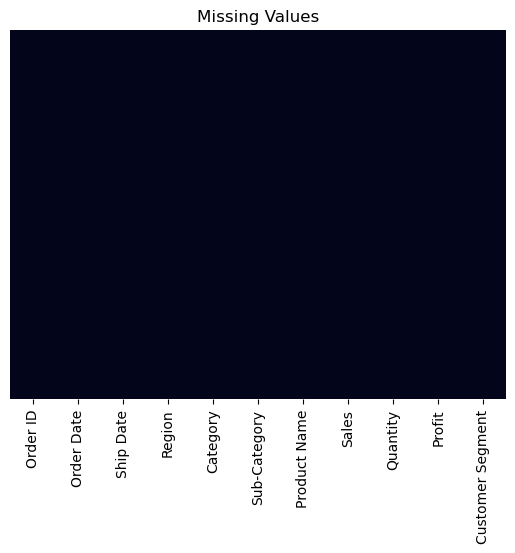

In [12]:
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values")
plt.show()

In [14]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Shape after cleaning:", df.shape)

Duplicate rows: 0
Shape after cleaning: (200, 11)


In [15]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()

df = df.replace(r"^\s*$", np.nan, regex=True)

display(df.head())

,Order ID,Order Date,Ship Date,Region,Category,Sub-Category,Product Name,Sales,Quantity,Profit,Customer Segment
0,ORD1000,2023-01-01,2023-01-03,Central,Technology,Chairs,Product B,365.04,8,19.84,Corporate
1,ORD1001,2023-01-02,2023-01-04,South,Technology,Accessories,Product A,996.25,6,23.97,Corporate
2,ORD1002,2023-01-03,2023-01-05,East,Furniture,Phones,Product C,727.23,3,58.93,Home Office
3,ORD1003,2023-01-04,2023-01-06,Central,Furniture,Binders,Product A,445.78,9,70.72,Home Office
4,ORD1004,2023-01-05,2023-01-07,Central,Office Supplies,Storage,Product D,763.39,2,219.91,Consumer


In [16]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)

print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [17]:
# Numeric columns: fill missing values with median
for col in df.select_dtypes(include="number").columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Categorical columns: fill with Unknown
for col in df.select_dtypes(
    include=["object", "string", "category"]
).columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna("Unknown")

# Check date issues separately
print(df[["Order Date", "Ship Date"]].isnull().sum())

Order Date    0
Ship Date     0
dtype: int64


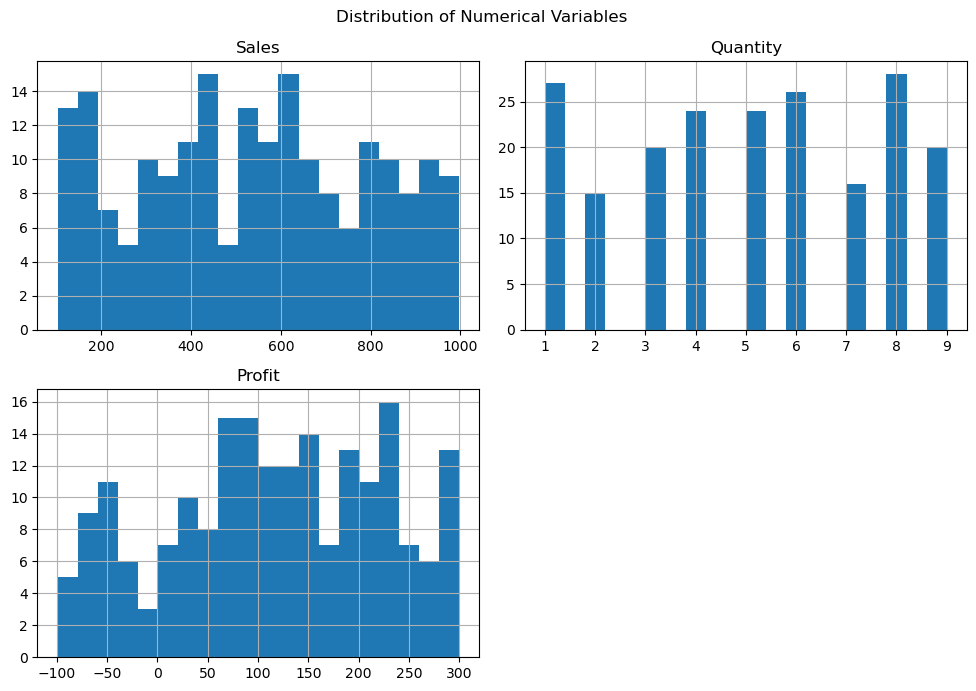

In [18]:
df[["Sales", "Quantity", "Profit"]].hist(figsize=(10, 7),bins=20)

plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()

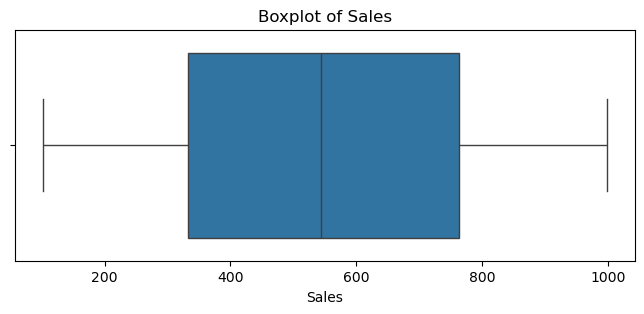

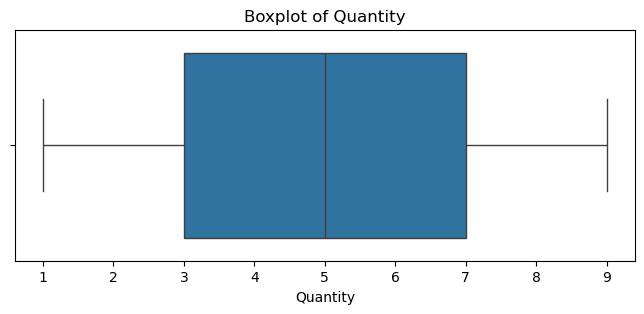

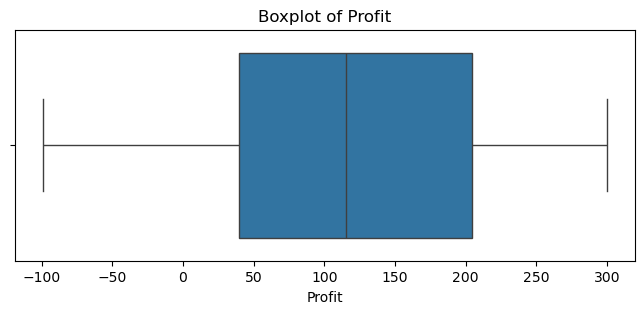

In [19]:
for col in ["Sales", "Quantity", "Profit"]:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [20]:
for col in ["Sales", "Quantity", "Profit"]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print("\nColumn:", col)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))


Column: Sales
Lower limit: -314.7099999999999
Upper limit: 1409.9499999999998
Number of outliers: 0

Column: Quantity
Lower limit: -3.0
Upper limit: 13.0
Number of outliers: 0

Column: Profit
Lower limit: -208.03250000000003
Upper limit: 451.6075000000001
Number of outliers: 0


In [21]:
# Calculate shipping duration
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Extract month, quarter and year
df["Order Month"] = df["Order Date"].dt.month_name()

df["Order Quarter"] = (
    "Q" + df["Order Date"].dt.quarter.astype("Int64").astype(str)
)

df["Order Year"] = df["Order Date"].dt.year.astype("Int64")

# Calculate profit margin
df["Profit Margin (%)"] = np.where(
    df["Sales"] != 0,
    (df["Profit"] / df["Sales"]) * 100,
    np.nan
)

display(df.head())

,Order ID,Order Date,Ship Date,Region,Category,Sub-Category,Product Name,Sales,Quantity,Profit,Customer Segment,Shipping Days,Order Month,Order Quarter,Order Year,Profit Margin (%)
0,ORD1000,2023-01-01,2023-01-03,Central,Technology,Chairs,Product B,365.04,8,19.84,Corporate,2,January,Q1,2023,5.435021
1,ORD1001,2023-01-02,2023-01-04,South,Technology,Accessories,Product A,996.25,6,23.97,Corporate,2,January,Q1,2023,2.406023
2,ORD1002,2023-01-03,2023-01-05,East,Furniture,Phones,Product C,727.23,3,58.93,Home Office,2,January,Q1,2023,8.103351
3,ORD1003,2023-01-04,2023-01-06,Central,Furniture,Binders,Product A,445.78,9,70.72,Home Office,2,January,Q1,2023,15.864328
4,ORD1004,2023-01-05,2023-01-07,Central,Office Supplies,Storage,Product D,763.39,2,219.91,Consumer,2,January,Q1,2023,28.807032


In [22]:
print("Negative sales:", (df["Sales"] < 0).sum())

print(
    "Zero or negative quantity:",
    (df["Quantity"] <= 0).sum()
)

print(
    "Shipping days below zero:",
    (df["Shipping Days"] < 0).sum()
)

Negative sales: 0
Zero or negative quantity: 0
Shipping days below zero: 0


In [23]:
df.to_csv("Superstore_Sales_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [28]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [29]:
# Define target and features
target = "Profit"

# Exclude identifiers, raw dates and leakage columns
exclude = [
    "Profit",
    "Profit Margin (%)",
    "Order ID",
    "Order Date",
    "Ship Date",
    "Product Name"]

In [30]:
X = df.drop(
    columns=[col for col in exclude if col in df.columns])

y = df[target]

In [31]:
# Separate numeric and categorical features
numeric_features = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

In [32]:
# Preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [33]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [34]:
# Build and train model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42))
])

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [35]:
# Predict
y_pred = model.predict(X_test)

In [36]:
# Evaluate model
print("MAE:", mean_absolute_error(y_test, y_pred))

print(
    "RMSE:",
    np.sqrt(mean_squared_error(y_test, y_pred))
)

print("R2 Score:", r2_score(y_test, y_pred))

MAE: 93.33559749999999
RMSE: 108.81289368055262
R2 Score: -0.04476634589555051


In [37]:
print("Final dataset shape:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum().sum())

print("\nRemaining duplicate rows:")
print(df.duplicated().sum())

print("\nFinal column names:")
print(df.columns.tolist())

print("\nFinal data types:")
print(df.dtypes)

Final dataset shape: (200, 16)

Remaining missing values:
0

Remaining duplicate rows:
0

Final column names:
['Order ID', 'Order Date', 'Ship Date', 'Region', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Profit', 'Customer Segment', 'Shipping Days', 'Order Month', 'Order Quarter', 'Order Year', 'Profit Margin (%)']

Final data types:
Order ID             string[python]
Order Date           datetime64[ns]
Ship Date            datetime64[ns]
Region               string[python]
Category             string[python]
Sub-Category         string[python]
Product Name         string[python]
Sales                       float64
Quantity                      int64
Profit                      float64
Customer Segment     string[python]
Shipping Days                 int64
Order Month                  object
Order Quarter                object
Order Year                    Int64
Profit Margin (%)           float64
dtype: object
